# Locating a thief zone with k-nearest neighbours

Kobby Sintim-Arthur, November 2026. This notebook reproduces every number and figure in the article, [`report/thief-zone-knn.pdf`](report/thief-zone-knn.pdf). Sections 1 to 8 follow the article.

**Result.** The suspect zone sits in the **Devonian**, in the 9.1 m interval between Devonian 3.1 (base 3454.7 m MD RKB) and the Lower Devonian (top 3463.8 m). The table's own averages place it there before any model runs, and kNN agrees in all 60 configurations tested. Depth fixes its position, its rock properties match the Upper Devonian zones and its water saturation matches the Lower Devonian. It holds 19% of the Devonian's net thickness and 90% of its flow capacity.

## 1. The problem

A thief zone is a thin, highly permeable layer that takes most of the water injected into a reservoir (Li et al., 2023). The brief, in summary:

| Brief | What it asked | Answered in |
|---|---|---|
| 1 | Geologists suspect a thief zone in the strata of the `petrophysical_data` worksheet | Sections 2 and 3 |
| 2 | Use kNN to identify the location of the thief zone, given its properties | Section 5 |
| 3 | Show the training data, labels and test point clearly in the code | Section 4 |
| 4 | Provide the code, the input file and a short report | This notebook, `data/`, `report/` |
| 5 | Explain which properties indicate the location of the thief zone | Section 6 |

Properties given for the suspect zone:

| Zone | Top (m) | Base (m) | N/G | PHIF | SW | KLOGH arith. (mD) | KLOGH harm. (mD) | KLOGH geom. (mD) |
|---|---|---|---|---|---|---|---|---|
| Suspect zone | 3455 | 3464 | 0.923 | 0.196 | 0.939 | 1280 | 48 | 358 |

In [1]:
%matplotlib inline
import numpy as np
import pandas as pd
from IPython.display import display

import plots
import thiefzone as tz

pd.set_option("display.precision", 3)
pd.set_option("display.width", 160)
FIGURES = "figures"

## 2. The data

One row per zone from a single well. Depths are in m MD RKB. N/G is net-to-gross, PHIF porosity, SW water saturation and KLOGH log-derived permeability, given as arithmetic, harmonic and geometric means. The arithmetic mean governs flow along the layers and the harmonic mean flow across them (Cardwell and Parsons, 1945). Injected water flows along the layers, so the arithmetic mean is used throughout.

In [2]:
table = tz.load_zone_table()
table[["zone", "level", "parent", "top", "base", "h", "ng", "phif", "sw", "k_ari", "k_har", "k_geo"]]

,zone,level,parent,top,base,h,ng,phif,sw,k_ari,k_har,k_geo
0,Zechstein,formation,NaN,3429.4,3435.0,5.6,0.000,NaN,NaN,NaN,NaN,NaN
1,Devonian,formation,NaN,3435.0,3500.2,65.2,0.692,0.168,0.899,263.0,0.5,10.0
2,Upper Devonian,unit,Devonian,3435.0,3454.7,19.7,0.822,0.170,0.819,65.0,0.5,15.0
3,Lower Devonian,unit,Devonian,3463.8,3500.2,36.4,0.565,0.156,0.946,4.0,0.4,1.5
4,Devonian 3.3 (12),zone,Upper Devonian,3435.0,3441.5,6.5,0.723,0.173,0.829,108.0,32.0,74.0
5,Devonian 3.2 (11),zone,Upper Devonian,3441.5,3448.0,6.5,0.923,0.178,0.760,66.0,3.0,26.0
6,Devonian 3.1 (10),zone,Upper Devonian,3448.0,3454.7,6.7,0.821,0.158,0.882,28.0,0.2,2.0
7,Rotliegend,formation,NaN,3500.2,3543.7,43.5,0.133,0.123,0.850,3.0,1.0,2.0
8,Crystalline basement,formation,NaN,3543.7,3608.0,64.3,0.723,0.135,0.975,0.7,0.3,0.4
9,Top basement,formation,NaN,3608.0,3682.0,74.0,0.051,0.119,0.973,0.3,0.2,0.2


## 3. Reading the table before modelling

**Devonian** is a formation, **Upper** and **Lower Devonian** are units within it, and **Devonian 3.3, 3.2 and 3.1** are zones within the Upper Devonian. If each parent row is a weighted average of its children, $\bar{x} = \sum w_i x_i / \sum w_i$, rolling up the children should reproduce it. N/G is weighted by gross thickness, porosity and the permeability means by net thickness, and water saturation by pore volume.

In [3]:
zones = table.set_index("zone")
check = ["h", "ng", "phif", "sw", "k_ari", "k_geo", "k_har"]
upper_children = zones.loc[["Devonian 3.3 (12)", "Devonian 3.2 (11)", "Devonian 3.1 (10)"]]
pd.DataFrame(
    {
        "Upper Devonian, reported": zones.loc["Upper Devonian", check],
        "rolled up from 3.3, 3.2, 3.1": pd.Series(tz.roll_up(upper_children))[check],
    }
)

,"Upper Devonian, reported","rolled up from 3.3, 3.2, 3.1"
h,19.700,19.700
ng,0.822,0.822
phif,0.170,0.170
sw,0.819,0.819
k_ari,65.000,65.281
k_geo,15.000,14.740
k_har,0.500,0.546


The Upper Devonian is reproduced. The Devonian cannot be: its arithmetic permeability (263 mD) is higher than both of its units (65 and 4 mD), and an average cannot exceed its largest part. The 9.1 m between 3454.7 and 3463.8 m has no row of its own. Converting each average back to a total (value times weight), subtracting the units from the Devonian and dividing by the remaining net thickness recovers that interval.

In [4]:
gap = tz.reconstruct_gap(table)
brief = tz.SUSPECT
pd.DataFrame(
    {
        "back-calculated from the Devonian row": [gap["top"], gap["base"], gap["ng"], gap["phif"], gap["sw"], gap["k_ari"]],
        "given for the suspect zone": [brief["top"], brief["base"], brief["ng"], brief["phif"], brief["sw"], brief["k_ari"]],
    },
    index=["top (m)", "base (m)", "N/G", "PHIF", "SW", "KLOGH arithmetic (mD)"],
)

,back-calculated from the Devonian row,given for the suspect zone
top (m),3454.700,3455.000
base (m),3463.800,3464.000
N/G,0.919,0.923
PHIF,0.194,0.196
SW,0.942,0.939
KLOGH arithmetic (mD),1283.802,1280.000


In [5]:
column = tz.devonian_column(table)
without_suspect = column[column["zone"] != tz.SUSPECT_NAME]
pd.DataFrame(
    {
        "Devonian, reported": zones.loc["Devonian", check],
        "rolled up without the gap": pd.Series(tz.roll_up(without_suspect))[check],
        "rolled up with the suspect zone in the gap": pd.Series(tz.roll_up(column))[check],
    }
)

,"Devonian, reported",rolled up without the gap,rolled up with the suspect zone in the gap
h,65.200,56.100,65.200
ng,0.692,0.655,0.693
phif,0.168,0.162,0.168
sw,0.899,0.887,0.899
k_ari,263.000,31.002,263.277
k_geo,10.000,4.106,9.424
k_har,0.500,0.454,0.556


The interval matches the suspect zone, and filling the gap with it reproduces the Devonian row, including the geometric and harmonic means, which were not used in the calculation. Without it the Devonian averages 31 mD.

The Devonian and Upper Devonian rows are therefore left out of training. They duplicate their children, and the Devonian row contains the suspect zone itself.

**Notes on the data.**

- The Zechstein has an N/G of 0 and no log values, as expected of the evaporites that seal the reservoir. It is used only in the depth-only view.
- The Rotliegend (Lower Permian) is listed beneath the Devonian, the reverse of normal age order. Zone names are used only as labels.
- The crystalline basement is 72% net with 0.7 mD. Net means it passes the evaluation's cut-offs; it does not mean the rock will flow. It is a training zone but takes no part in the flow analysis, which covers the Devonian only.

## 4. Setting up kNN

- **Training data**: the seven non-overlapping rows: Devonian 3.3, 3.2 and 3.1, the Lower Devonian, the Rotliegend and the two basement zones. The Zechstein is added in the depth-only view.
- **Labels**: the formation of each training zone (Devonian, Rotliegend, Basement, and Zechstein in the depth-only view). Four training zones are labelled Devonian; the Devonian row itself is not used.
- **Test point**: the suspect zone's eight properties.
- **Features**: three views, stratigraphic, petrophysical and all eight. Permeability is log-transformed because it spans more than three orders of magnitude. The scaler is fitted on the training rows only.

In [6]:
train = tz.leaf_catalogue(table)
train_with_seal = tz.leaf_catalogue(table, include_zechstein=True)
test = tz.suspect_frame()

print("Training data and labels")
display(train[["zone", "formation", "top", "base", "ng", "phif", "sw", "k_ari", "k_har", "k_geo"]])
print("Test point")
display(test[["zone", "top", "base", "ng", "phif", "sw", "k_ari", "k_har", "k_geo"]])
print("Feature views")
for view, features in tz.FEATURE_VIEWS.items():
    print(f"  {view:14s} {features}")

Training data and labels


,zone,formation,top,base,ng,phif,sw,k_ari,k_har,k_geo
0,Devonian 3.3 (12),Devonian,3435.0,3441.5,0.723,0.173,0.829,108.0,32.0,74.0
1,Devonian 3.2 (11),Devonian,3441.5,3448.0,0.923,0.178,0.760,66.0,3.0,26.0
2,Devonian 3.1 (10),Devonian,3448.0,3454.7,0.821,0.158,0.882,28.0,0.2,2.0
3,Lower Devonian,Devonian,3463.8,3500.2,0.565,0.156,0.946,4.0,0.4,1.5
4,Rotliegend,Rotliegend,3500.2,3543.7,0.133,0.123,0.850,3.0,1.0,2.0
5,Crystalline basement,Basement,3543.7,3608.0,0.723,0.135,0.975,0.7,0.3,0.4
6,Top basement,Basement,3608.0,3682.0,0.051,0.119,0.973,0.3,0.2,0.2


Test point


,zone,top,base,ng,phif,sw,k_ari,k_har,k_geo
0,Suspect zone,3455.0,3464.0,0.923,0.196,0.939,1280.0,48.0,358.0


Feature views
  stratigraphic  ['top', 'base']
  petrophysical  ['ng', 'phif', 'sw', 'log_k_ari', 'log_k_har', 'log_k_geo']
  all            ['top', 'base', 'ng', 'phif', 'sw', 'log_k_ari', 'log_k_har', 'log_k_geo']


## 5. Where the zone sits

Each feature is scaled to standard deviations from the training mean. kNN then measures the straight-line distance from the suspect zone to every training zone and takes a majority vote of the *k* nearest.

In [7]:
summary = []
neighbour_tables = {}
for view, features in tz.FEATURE_VIEWS.items():
    reference = train_with_seal if view == "stratigraphic" else train
    votes = {}
    for k in (1, 3, 5):
        votes[f"k={k}"], neighbours = tz.locate(reference, test, features, k=k)
    neighbour_tables[view] = neighbours
    summary.append({"view": view, **votes, "nearest zone": neighbours.loc[0, "zone"], "second nearest": neighbours.loc[1, "zone"]})
pd.DataFrame(summary)

,view,k=1,k=3,k=5,nearest zone,second nearest
0,stratigraphic,Devonian,Devonian,Devonian,Devonian 3.1 (10),Devonian 3.2 (11)
1,petrophysical,Devonian,Devonian,Devonian,Devonian 3.3 (12),Devonian 3.2 (11)
2,all,Devonian,Devonian,Devonian,Devonian 3.3 (12),Devonian 3.2 (11)


In [8]:
distances = {view: neighbours.set_index("zone")["distance"] for view, neighbours in neighbour_tables.items()}
distance_table = pd.DataFrame(distances).reindex(train_with_seal["zone"])
distance_table.insert(0, "formation", train_with_seal.set_index("zone")["formation"])
for view, neighbours in neighbour_tables.items():
    counts = neighbours.head(5)["formation"].value_counts()
    print(f"k=5 vote, {view}: " + ", ".join(f"{name} {count}" for name, count in counts.items()))
distance_table

k=5 vote, stratigraphic: Devonian 4, Zechstein 1
k=5 vote, petrophysical: Devonian 4, Rotliegend 1
k=5 vote, all: Devonian 4, Rotliegend 1


,formation,stratigraphic,petrophysical,all
zone,,,,
Zechstein,Zechstein,0.55,NaN,NaN
Devonian 3.3 (12),Devonian,0.43,2.40,2.44
Devonian 3.2 (11),Devonian,0.30,3.57,3.58
Devonian 3.1 (10),Devonian,0.16,4.92,4.93
Lower Devonian,Devonian,0.45,5.27,5.29
Rotliegend,Rotliegend,1.21,6.27,6.39
Crystalline basement,Basement,2.26,6.49,6.87
Top basement,Basement,3.64,7.81,8.62


One distance by hand: the suspect zone to Devonian 3.1 in the stratigraphic view.

In [9]:
features = tz.FEATURE_VIEWS["stratigraphic"]
scaler = tz.make_scaler("standard").fit(train_with_seal[features])
z_suspect = scaler.transform(test[features])[0]
z_31 = scaler.transform(train_with_seal.loc[train_with_seal["zone"] == "Devonian 3.1 (10)", features])[0]
print("suspect zone, scaled top and base:", z_suspect.round(3))
print("Devonian 3.1, scaled top and base:", z_31.round(3))
print(f"distance = sqrt({z_suspect[0] - z_31[0]:.3f}^2 + {z_suspect[1] - z_31[1]:.3f}^2) = {np.sqrt(((z_suspect - z_31) ** 2).sum()):.2f}")

suspect zone, scaled top and base: [-0.484 -0.591]
Devonian 3.1, scaled top and base: [-0.602 -0.701]
distance = sqrt(0.118^2 + 0.110^2) = 0.16


In every view the three nearest zones are Devonian, so the vote is Devonian at *k* = 1, 3 and 5 (four to one at *k* = 5). By depth the nearest zone is Devonian 3.1, directly above the gap. In the petrophysical and all-eight views it is Devonian 3.3, the best rock in the Upper Devonian.

r35 is the Winland pore-throat radius at 35% mercury saturation, estimated from porosity and permeability (Kolodzie, 1980; Pittman, 1992), with port classes from Martin et al. (1997).

In [10]:
r35 = {name: float(tz.winland_r35(row["k_ari"], row["phif"])) for name, row in pd.concat([train, test]).set_index("zone").iterrows()}
pd.DataFrame({"r35 (µm)": r35, "port class": {z: tz.port_class(v) for z, v in r35.items()}}).sort_values("r35 (µm)", ascending=False)

,r35 (µm),port class
Suspect zone,27.703,megaport
Devonian 3.3 (12),7.211,macroport
Devonian 3.2 (11),5.267,macroport
Devonian 3.1 (10),3.526,macroport
Rotliegend,1.177,mesoport
Lower Devonian,1.135,mesoport
Crystalline basement,0.462,microport
Top basement,0.313,microport


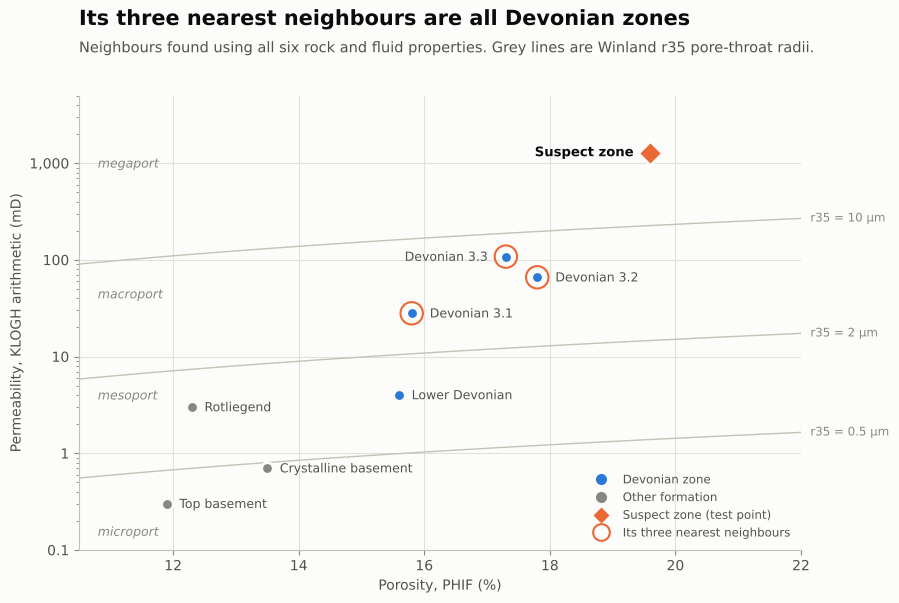

In [11]:
fig = plots.rock_space(train, test, neighbour_tables["petrophysical"]["zone"].head(3).tolist(), path=f"{FIGURES}/knn-rock-space.png")

The suspect zone has higher porosity and permeability than every training zone and is the only megaport rock in the well. kNN can place it in the Devonian but cannot show that its rock is new; Section 7 does that.

## 6. Which properties point to it

The closest training zone on each property alone, then the full model with each property removed in turn.

In [12]:
properties = tz.FEATURE_VIEWS["all"]
nearest = tz.nearest_by_property(train, test, properties)
nearest

,property,suspect,nearest zone,nearest value,gap (sd),outside training range
0,top,3455.000,Devonian 3.1 (10),3448.000,0.12,False
1,base,3464.000,Devonian 3.1 (10),3454.700,0.11,False
2,ng,0.923,Devonian 3.2 (11),0.923,0.00,False
3,phif,0.196,Devonian 3.2 (11),0.178,0.83,True
4,sw,0.939,Lower Devonian,0.946,0.09,False
5,log_k_ari,3.107,Devonian 3.3 (12),2.033,1.18,True
6,log_k_har,1.681,Devonian 3.3 (12),1.505,0.24,True
7,log_k_geo,2.554,Devonian 3.3 (12),1.869,0.80,True


In [13]:
ablation = []
for dropped in properties:
    kept = [p for p in properties if p != dropped]
    vote, neighbours = tz.locate(train, test, kept, k=3)
    ablation.append({"property removed": dropped, "formation (k=3)": vote, "nearest zone": neighbours.loc[0, "zone"]})
pd.DataFrame(ablation)

,property removed,formation (k=3),nearest zone
0,top,Devonian,Devonian 3.3 (12)
1,base,Devonian,Devonian 3.3 (12)
2,ng,Devonian,Devonian 3.3 (12)
3,phif,Devonian,Devonian 3.3 (12)
4,sw,Devonian,Devonian 3.3 (12)
5,log_k_ari,Devonian,Devonian 3.3 (12)
6,log_k_har,Devonian,Devonian 3.3 (12)
7,log_k_geo,Devonian,Devonian 3.3 (12)


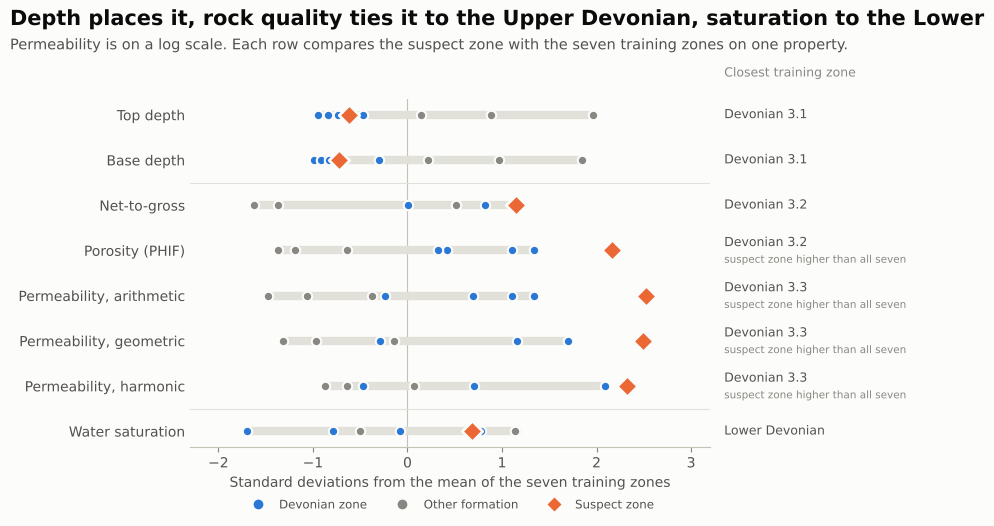

In [14]:
fig = plots.property_fingerprint(train, test, nearest, path=f"{FIGURES}/property-fingerprint.png")

- **Depth locates it.** Top and base are closest to Devonian 3.1, the zone above, with the Lower Devonian almost as close below.
- **Rock quality identifies it.** All three permeability means are closest to Devonian 3.3, and N/G and porosity to Devonian 3.2. Porosity and every permeability mean are higher than in any zone in the well.
- **Saturation sets it apart from the rock above.** Water saturation is closest to the Lower Devonian (0.939 against 0.946).

Removing any one property still gives Devonian, with Devonian 3.3 nearest.

## 7. Does it behave like a thief zone?

With the suspect zone in its gap, the Devonian has five layers. Flow capacity is permeability times net thickness (*kh*) and storage capacity is porosity times net thickness (*φh*).

In [15]:
profile = tz.flow_profile(column)
profile[["zone", "h", "h_net", "phif", "k_ari", "kh", "phih", "net_share", "storage_share", "flow_share", "flow_to_storage"]]

,zone,h,h_net,phif,k_ari,kh,phih,net_share,storage_share,flow_share,flow_to_storage
0,Devonian 3.3 (12),6.5,4.699,0.173,108.0,507.546,0.813,0.104,0.107,0.043,0.399
1,Devonian 3.2 (11),6.5,6.000,0.178,66.0,395.967,1.068,0.133,0.140,0.033,0.237
2,Devonian 3.1 (10),6.7,5.501,0.158,28.0,154.020,0.869,0.122,0.114,0.013,0.113
3,Suspect zone,9.1,8.399,0.196,1280.0,10751.104,1.646,0.186,0.216,0.904,4.177
4,Lower Devonian,36.4,20.566,0.156,4.0,82.264,3.208,0.455,0.422,0.007,0.016


In [16]:
p = profile.set_index("zone")
s = p.loc[tz.SUSPECT_NAME]
host = profile[profile["zone"] != tz.SUSPECT_NAME]
host_k = host["kh"].sum() / host["h_net"].sum()
pd.Series(
    {
        "share of Devonian net thickness": f"{s['net_share']:.1%}",
        "share of Devonian storage capacity": f"{s['storage_share']:.1%}",
        "share of Devonian flow capacity": f"{s['flow_share']:.1%}",
        "permeability vs zone above (3.1)": f"{s['k_ari'] / p.loc['Devonian 3.1 (10)', 'k_ari']:.0f}x",
        "permeability vs zone below (Lower Devonian)": f"{s['k_ari'] / p.loc['Lower Devonian', 'k_ari']:.0f}x",
        "permeability vs rest of the Devonian (net-weighted)": f"{s['k_ari'] / host_k:.0f}x ({host_k:.0f} mD)",
        "front speed vs next best layer (3.3)": f"{s['speed'] / p.loc['Devonian 3.3 (12)', 'speed']:.1f}x",
        "harmonic mean vs highest of the other zones": f"{s['k_har']:.0f} mD vs {train['k_har'].max():.0f} mD",
    },
    name="value",
).to_frame()

,value
share of Devonian net thickness,18.6%
share of Devonian storage capacity,21.6%
share of Devonian flow capacity,90.4%
permeability vs zone above (3.1),46x
permeability vs zone below (Lower Devonian),320x
permeability vs rest of the Devonian (net-weighted),41x (31 mD)
front speed vs next best layer (3.3),10.5x
harmonic mean vs highest of the other zones,48 mD vs 32 mD


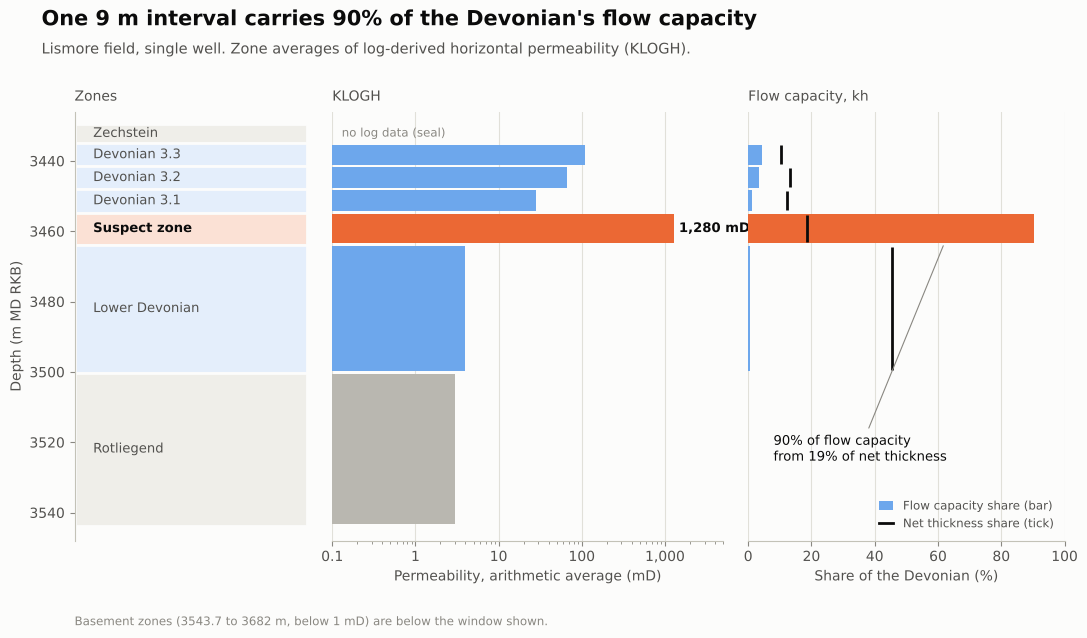

In [17]:
fig = plots.well_section(table, path=f"{FIGURES}/well-section.png")

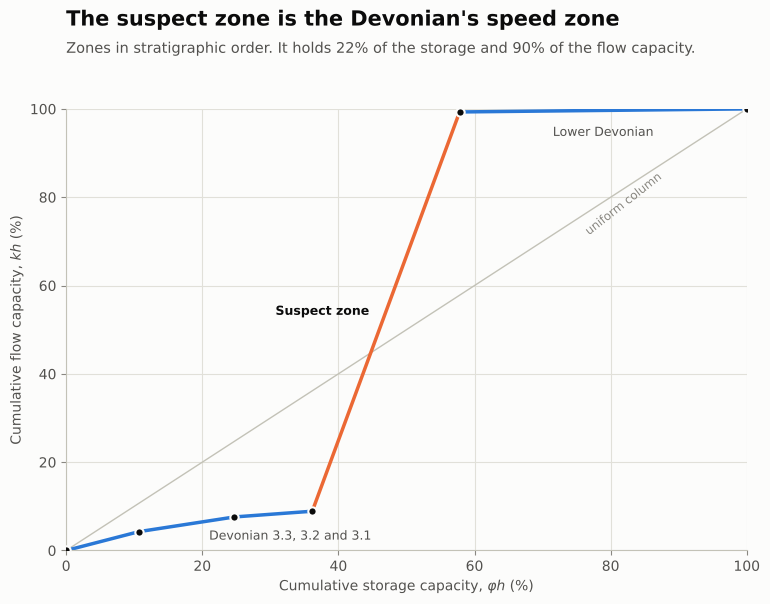

In [18]:
fig = plots.lorenz_plot(profile, path=f"{FIGURES}/lorenz-plot.png")

The zone holds 19% of the Devonian's net thickness and 22% of its storage, but 90% of its flow capacity. With no crossflow and similar mobilities, injected water splits in proportion to *kh*, and the flood front in this zone moves about ten times faster than in Devonian 3.3. On the stratigraphic modified Lorenz plot it is a speed zone (Gunter et al., 1997).

It is 46 times as permeable as the zone above, 320 times the zone below and 41 times the rest of the Devonian. Li et al. (2023) used 2.8 times the surrounding average as a thief-zone threshold in an Iraqi carbonate field.

Its harmonic mean (48 mD) is the highest in the well, so the interval has no tight beds of consequence. Its water saturation of 0.939 fits a zone already swept by injected water, and also rock near the oil-water contact. Within the Devonian, water saturation rises with depth from zone 3.2 (0.76) to the Lower Devonian (0.95), so saturation alone cannot tell the two apart.

## 8. How far to trust the result

The grid varies the feature view, *k*, the scaler, log or linear permeability, and whether the parent rows are wrongly left in the training data.

In [19]:
parent_rows = tz.add_log_perm(table[table["zone"].isin(tz.PARENT_ROWS)])
grid = []
for view, features in tz.FEATURE_VIEWS.items():
    permeability_scales = ["log"] if view == "stratigraphic" else ["log", "linear"]
    for scale in permeability_scales:
        used = [f.replace("log_", "") for f in features] if scale == "linear" else features
        for training_set in ("leaf zones", "leaf zones + parent rows"):
            reference = train_with_seal if view == "stratigraphic" else train
            if training_set != "leaf zones":
                reference = pd.concat([reference, parent_rows], ignore_index=True)
            for scaler in ("standard", "minmax"):
                for k in (1, 3, 5):
                    vote, neighbours = tz.locate(reference, test, used, k=k, scaler=scaler)
                    grid.append(
                        {"view": view, "permeability": scale, "training": training_set, "scaler": scaler, "k": k, "formation": vote, "nearest": neighbours.loc[0, "zone"]}
                    )
grid = pd.DataFrame(grid)
print(f"{(grid['formation'] == 'Devonian').sum()} of {len(grid)} configurations place the suspect zone in the Devonian")
grid.groupby(["view", "permeability"])[["formation", "nearest"]].agg(lambda values: ", ".join(sorted(set(values))))

60 of 60 configurations place the suspect zone in the Devonian


formation            nearest
view          permeability                             
all           linear        Devonian  Devonian 3.3 (12)
              log           Devonian  Devonian 3.3 (12)
petrophysical linear        Devonian  Devonian 3.3 (12)
              log           Devonian  Devonian 3.3 (12)
stratigraphic log           Devonian  Devonian 3.1 (10)

Hold-out check: each training zone is located from the other six.

In [20]:
holdout = []
for view in ("petrophysical", "all"):
    features = tz.FEATURE_VIEWS[view]
    for i in train.index:
        vote, _ = tz.locate(train.drop(i), train.loc[[i]], features, k=1)
        holdout.append({"view": view, "held-out zone": train.loc[i, "zone"], "true formation": train.loc[i, "formation"], "predicted": vote})
holdout = pd.DataFrame(holdout)
holdout["correct"] = holdout["true formation"] == holdout["predicted"]
display(holdout.pivot(index="held-out zone", columns="view", values="predicted"))
holdout.groupby(["view", "true formation"])["correct"].agg(["sum", "count"])

view,all,petrophysical
held-out zone,,
Crystalline basement,Devonian,Devonian
Devonian 3.1 (10),Devonian,Devonian
Devonian 3.2 (11),Devonian,Devonian
Devonian 3.3 (12),Devonian,Devonian
Lower Devonian,Devonian,Devonian
Rotliegend,Devonian,Basement
Top basement,Basement,Rotliegend


sum  count
view          true formation            
all           Basement          1      2
              Devonian          4      4
              Rotliegend        0      1
petrophysical Basement          0      2
              Devonian          4      4
              Rotliegend        0      1

All 60 configurations place the zone in the Devonian. The nearest zone is always Devonian 3.1 in the stratigraphic view and 3.3 in the other two. In the hold-out check every Devonian zone is placed in the Devonian. The Rotliegend has no other example, and the two basement zones differ from each other more than from their neighbours. With seven rows, the table is a reference catalogue for one well.

**Limitations.** One well's zone averages cannot show whether the zone is continuous between injectors and producers. KLOGH is a log model and would normally be calibrated against core. The zone's permeability is about three times what the porosity trend of the other zones predicts (about 390 mD), which could mean coarser grains or fractures. The water split assumes no crossflow.

**What would confirm it.** Injection and production logging, interwell tracer tests, formation pressure tests and time-lapse saturation logs.

## References

- Cardwell, W.T. and Parsons, R.L. (1945). Average permeabilities of heterogeneous oil sands. *Transactions of the AIME*, 160, 34-42.
- Cover, T. and Hart, P. (1967). Nearest neighbor pattern classification. *IEEE Transactions on Information Theory*, 13(1), 21-27.
- Gunter, G.W., Finneran, J.M., Hartmann, D.J. and Miller, J.D. (1997). Early determination of reservoir flow units using an integrated petrophysical method. Paper SPE 38679.
- Kolodzie, S. (1980). Analysis of pore throat size and use of the Waxman-Smits equation to determine OOIP in Spindle Field, Colorado. Paper SPE 9382.
- Li, R., Deng, H., Fu, M., Hu, L., Xie, X., Zhang, L. and Guo, X. (2023). Identification method of thief zones in carbonate reservoirs based on the combination of static and dynamic data: a case study from the Cretaceous Mishrif Formation in the H oilfield, Iraq. *Frontiers in Energy Research*, 10, 1043231. https://doi.org/10.3389/fenrg.2022.1043231
- Martin, A.J., Solomon, S.T. and Hartmann, D.J. (1997). Characterization of petrophysical flow units in carbonate reservoirs. *AAPG Bulletin*, 81(5), 734-759.
- Pittman, E.D. (1992). Relationship of porosity and permeability to various parameters derived from mercury injection-capillary pressure curves for sandstone. *AAPG Bulletin*, 76(2), 191-198.

Dark versions of Figures 1 and 2, for presentations.

In [21]:
import matplotlib.pyplot as plt

plt.close(plots.well_section(table, theme="dark", path=f"{FIGURES}/well-section-dark.png"))
plt.close(plots.rock_space(train, test, neighbour_tables["petrophysical"]["zone"].head(3).tolist(), theme="dark", path=f"{FIGURES}/knn-rock-space-dark.png"))